In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "data" / "processed").exists():
    PROJECT_DIR = PROJECT_DIR.parent

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

customers = pd.read_csv(
    PROCESSED_DIR / "customers.csv",
    parse_dates=["signup_date"]
)

orders = pd.read_csv(
    PROCESSED_DIR / "orders.csv",
    parse_dates=["order_time"]
)

deliveries = pd.read_csv(
    PROCESSED_DIR / "deliveries.csv",
    parse_dates=["pickup_time", "delivery_time"]
)

reviews = pd.read_csv(PROCESSED_DIR / "reviews.csv")

print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Deliveries:", deliveries.shape)
print("Reviews:", reviews.shape)

display(customers.head())
display(orders.head())


Customers: (1000, 4)
Orders: (5000, 6)
Deliveries: (4075, 6)
Reviews: (2445, 4)


,customer_id,signup_date,city,customer_segment
0,1,2024-03-30,Pune,New
1,2,2026-02-16,Mumbai,Regular
2,3,2025-10-19,Hyderabad,New
3,4,2025-03-16,Pune,New
4,5,2025-03-10,Chennai,Regular


,order_id,customer_id,restaurant_id,order_time,order_value,status
0,10001,318,123,2025-05-26 23:05:00,1067.20,Completed
1,10002,843,101,2025-09-29 06:00:00,991.14,Cancelled
2,10003,36,134,2025-02-02 14:29:00,983.60,Completed
3,10004,447,123,2025-11-26 01:47:00,389.39,Cancelled
4,10005,801,139,2025-07-08 04:12:00,911.09,Completed


In [2]:

# Aggregate order behavior for each customer
customer_orders = orders.groupby("customer_id").agg(
    total_orders=("order_id", "count"),
    completed_orders=("status", lambda s: (s == "Completed").sum()),
    cancelled_orders=("status", lambda s: (s == "Cancelled").sum()),
    total_spend=("order_value", lambda s: s[orders.loc[s.index, "status"].eq("Completed")].sum()),
    avg_order_value=("order_value", lambda s: s[orders.loc[s.index, "status"].eq("Completed")].mean())
).reset_index()

# Start with every customer, including those with no orders
customer_features = customers[["customer_id", "city"]].merge(
    customer_orders,
    on="customer_id",
    how="left"
)

# Customers with no orders receive zero order counts and spending
count_cols = [
    "total_orders",
    "completed_orders",
    "cancelled_orders",
    "total_spend"
]

customer_features[count_cols] = (
    customer_features[count_cols].fillna(0)
)

# An average order value is zero here only when no completed order exists
customer_features["avg_order_value"] = (
    customer_features["avg_order_value"].fillna(0)
)

# Calculate cancellation rate safely
customer_features["cancellation_rate"] = np.where(
    customer_features["total_orders"] > 0,
    customer_features["cancelled_orders"]
    / customer_features["total_orders"],
    0
)

print("Customer feature table:", customer_features.shape)
display(customer_features.head(10))


Customer feature table: (1000, 8)


,customer_id,city,total_orders,completed_orders,cancelled_orders,total_spend,avg_order_value,cancellation_rate
0,1,Pune,6.0,6.0,0.0,4355.30,725.883333,0.000000
1,2,Mumbai,3.0,3.0,0.0,2311.82,770.606667,0.000000
2,3,Hyderabad,4.0,3.0,1.0,2640.11,880.036667,0.250000
3,4,Pune,6.0,5.0,1.0,3335.64,667.128000,0.166667
4,5,Chennai,9.0,7.0,2.0,4170.99,595.855714,0.222222
5,6,Pune,3.0,3.0,0.0,2447.55,815.850000,0.000000
6,7,Pune,5.0,4.0,1.0,3621.98,905.495000,0.200000
7,8,Hyderabad,7.0,7.0,0.0,4061.78,580.254286,0.000000
8,9,Mumbai,4.0,3.0,1.0,2704.53,901.510000,0.250000
9,10,Hyderabad,2.0,1.0,0.0,1034.01,1034.010000,0.000000


In [3]:

print("Number of customers:", len(customer_features))
print("Unique customer IDs:", customer_features["customer_id"].nunique())
print("Duplicate customer IDs:", customer_features["customer_id"].duplicated().sum())
print("Missing values:\n", customer_features.isnull().sum())

print("\nCustomer behavior summary:")
display(
    customer_features[
        [
            "total_orders",
            "completed_orders",
            "total_spend",
            "avg_order_value",
            "cancellation_rate"
        ]
    ].describe().round(2)
)

# Save the engineered features
output_path = PROCESSED_DIR / "customer_features.csv"
customer_features.to_csv(output_path, index=False)

print(f"\nSaved to: {output_path}")


Number of customers: 1000
Unique customer IDs: 1000
Duplicate customer IDs: 0
Missing values:
 customer_id          0
city                 0
total_orders         0
completed_orders     0
cancelled_orders     0
total_spend          0
avg_order_value      0
cancellation_rate    0
dtype: int64

Customer behavior summary:


,total_orders,completed_orders,total_spend,avg_order_value,cancellation_rate
count,1000.00,1000.00,1000.00,1000.00,1000.00
mean,5.00,4.08,3247.34,779.44,0.12
std,2.24,1.98,1797.74,245.47,0.16
min,0.00,0.00,0.00,0.00,0.00
25%,3.00,3.00,1911.35,641.66,0.00
50%,5.00,4.00,3076.58,789.97,0.00
75%,6.25,5.00,4376.27,930.39,0.20
max,14.00,11.00,9560.75,1485.51,1.00



Saved to: /home/nineleaps/Downloads/Uber Eats/data/processed/customer_features.csv


In [4]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

features = [
    "total_orders",
    "completed_orders",
    "cancelled_orders",
    "total_spend",
    "avg_order_value",
    "cancellation_rate"
]

X = customer_features[features].copy()

# Scale each feature to a comparable range
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original feature shape:", X.shape)
print("Scaled feature shape:", X_scaled.shape)
print("\nScaled feature means:")
print(pd.Series(X_scaled.mean(axis=0), index=features).round(3))


Original feature shape: (1000, 6)
Scaled feature shape: (1000, 6)

Scaled feature means:
total_orders         0.0
completed_orders    -0.0
cancelled_orders     0.0
total_spend         -0.0
avg_order_value     -0.0
cancellation_rate    0.0
dtype: float64


,k,inertia,silhouette_score
0,2,4126.352,0.291
1,3,3018.100,0.330
2,4,2632.281,0.296
3,5,2278.118,0.274
4,6,2028.766,0.276
5,7,1805.618,0.287
6,8,1628.878,0.295


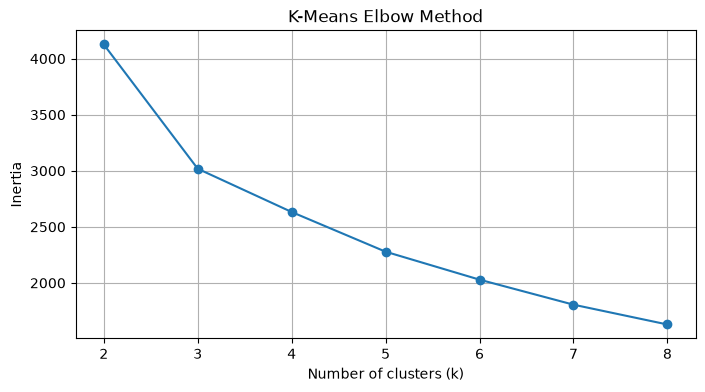

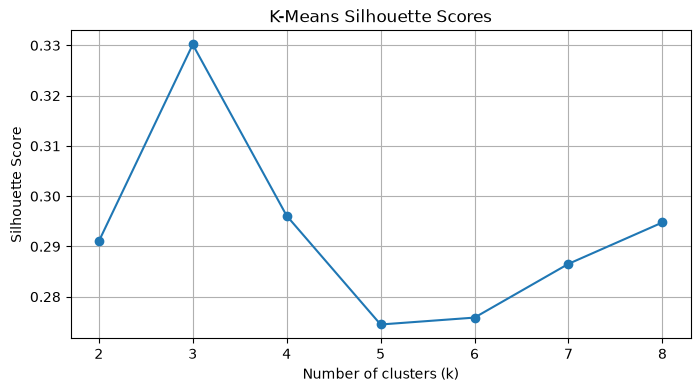

In [5]:

inertias = []
silhouette_scores = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

results = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "silhouette_score": silhouette_scores
})

display(results.round(3))

# Elbow plot
plt.figure(figsize=(8, 4))
plt.plot(results["k"], results["inertia"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Silhouette plot
plt.figure(figsize=(8, 4))
plt.plot(
    results["k"],
    results["silhouette_score"],
    marker="o"
)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Scores")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


In [6]:

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

customer_features["kmeans_cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster sizes:")
print(
    customer_features["kmeans_cluster"]
    .value_counts()
    .sort_index()
)

print("\nCluster profiles:")
cluster_profile = customer_features.groupby(
    "kmeans_cluster"
)[features].mean().round(2)

display(cluster_profile)


Cluster sizes:
kmeans_cluster
0    386
1    315
2    299
Name: count, dtype: int64

Cluster profiles:


,total_orders,completed_orders,cancelled_orders,total_spend,avg_order_value,cancellation_rate
kmeans_cluster,,,,,,
0,3.24,2.98,0.00,2238.17,735.60,0.00
1,7.35,6.34,0.63,5242.99,834.10,0.08
2,4.80,3.09,1.39,2447.72,778.45,0.31


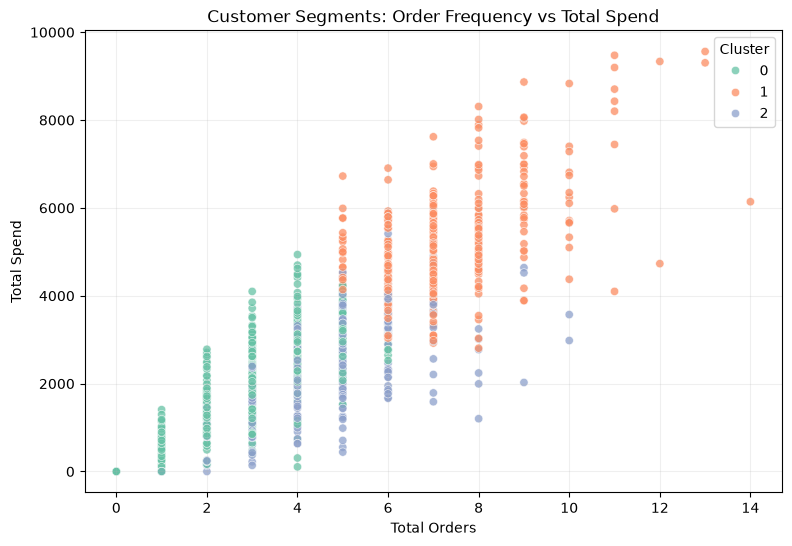

In [7]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=customer_features,
    x="total_orders",
    y="total_spend",
    hue="kmeans_cluster",
    palette="Set2",
    alpha=0.75
)

plt.title("Customer Segments: Order Frequency vs Total Spend")
plt.xlabel("Total Orders")
plt.ylabel("Total Spend")
plt.legend(title="Cluster")
plt.grid(alpha=0.2)
plt.show()


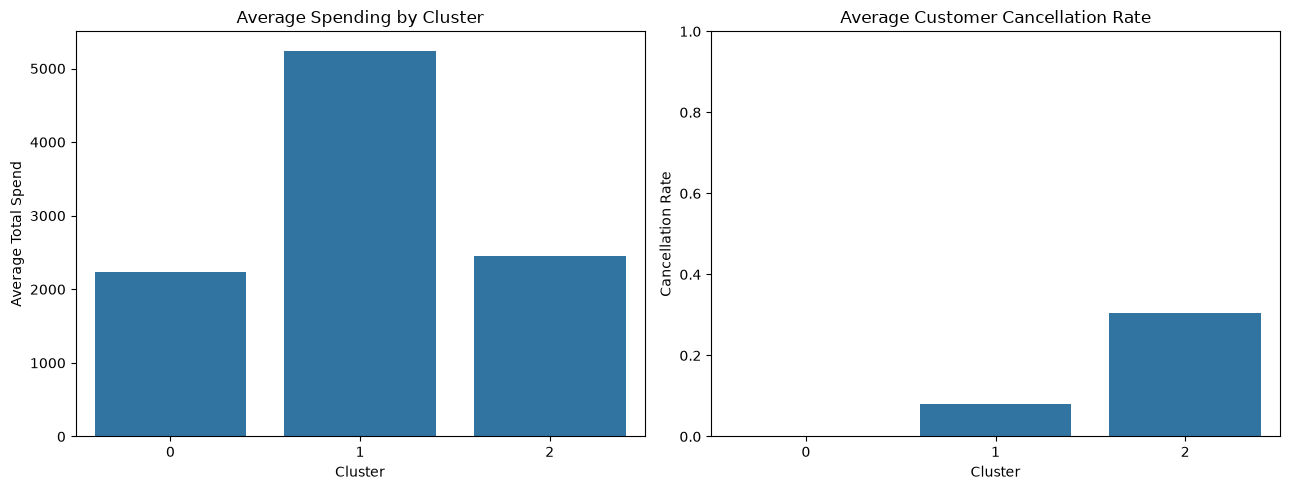

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=customer_features,
    x="kmeans_cluster",
    y="total_spend",
    estimator="mean",
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title("Average Spending by Cluster")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Average Total Spend")

sns.barplot(
    data=customer_features,
    x="kmeans_cluster",
    y="cancellation_rate",
    estimator="mean",
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title("Average Customer Cancellation Rate")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Cancellation Rate")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()


In [9]:

from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=1.2,
    min_samples=10
)

customer_features["dbscan_cluster"] = dbscan.fit_predict(X_scaled)

print("DBSCAN cluster counts:")
print(
    customer_features["dbscan_cluster"]
    .value_counts()
    .sort_index()
)

noise_count = (customer_features["dbscan_cluster"] == -1).sum()

print("\nNoise points:", noise_count)
print("Noise percentage:", round(noise_count / len(customer_features) * 100, 2), "%")


DBSCAN cluster counts:
dbscan_cluster
-1     48
 0    534
 1    338
 2     80
Name: count, dtype: int64

Noise points: 48
Noise percentage: 4.8 %


In [10]:
# Calculate average customer behavior for each DBSCAN cluster
dbscan_profile = customer_features.groupby("dbscan_cluster").agg(
    customer_count=("customer_id", "count"),
    avg_orders=("total_orders", "mean"),
    avg_completed=("completed_orders", "mean"),
    avg_cancelled=("cancelled_orders", "mean"),
    avg_spend=("total_spend", "mean"),
    avg_order_value=("avg_order_value", "mean"),
    avg_cancellation_rate=("cancellation_rate", "mean")
).round(2)

print(dbscan_profile)

                customer_count  avg_orders  avg_completed  avg_cancelled  \
dbscan_cluster                                                             
-1                          48        6.81           4.00           2.46   
 0                         534        4.23           3.94           0.00   
 1                         338        5.63           4.30           1.00   
 2                          80        6.40           4.06           2.00   

                avg_spend  avg_order_value  avg_cancellation_rate  
dbscan_cluster                                                     
-1                3283.71           767.41                   0.47  
 0                3089.84           763.30                   0.00  
 1                3446.20           792.34                   0.20  
 2                3436.66           839.88                   0.33  


In [11]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Reduce six features to two principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Store PCA coordinates
customer_features["PCA1"] = X_pca[:, 0]
customer_features["PCA2"] = X_pca[:, 1]

print(
    "Variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Variance explained: 80.16 %


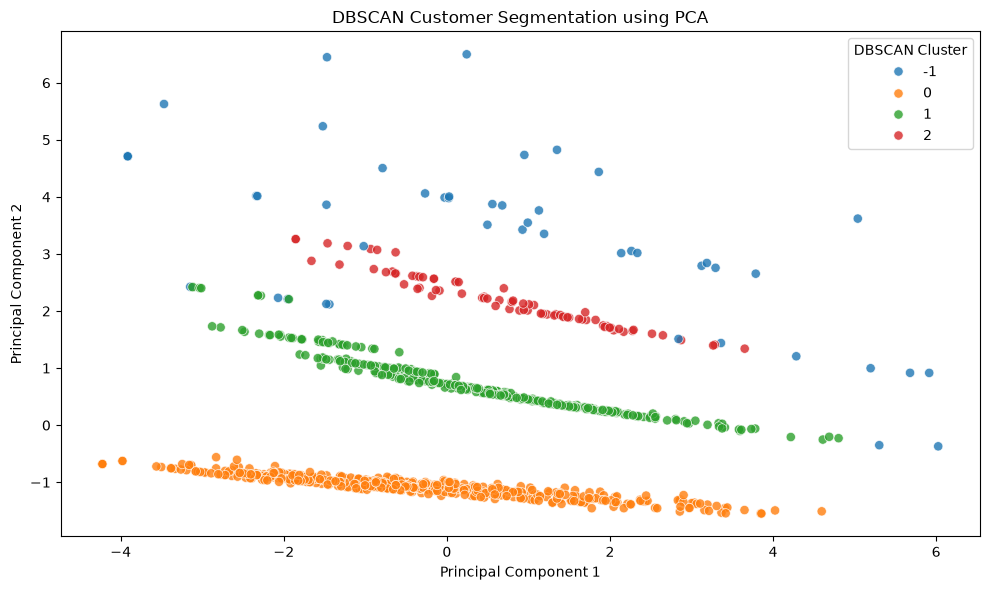

In [12]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=customer_features,
    x="PCA1",
    y="PCA2",
    hue="dbscan_cluster",
    palette="tab10",
    s=45,
    alpha=0.8
)

plt.title("DBSCAN Customer Segmentation using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="DBSCAN Cluster")
plt.tight_layout()
plt.show()

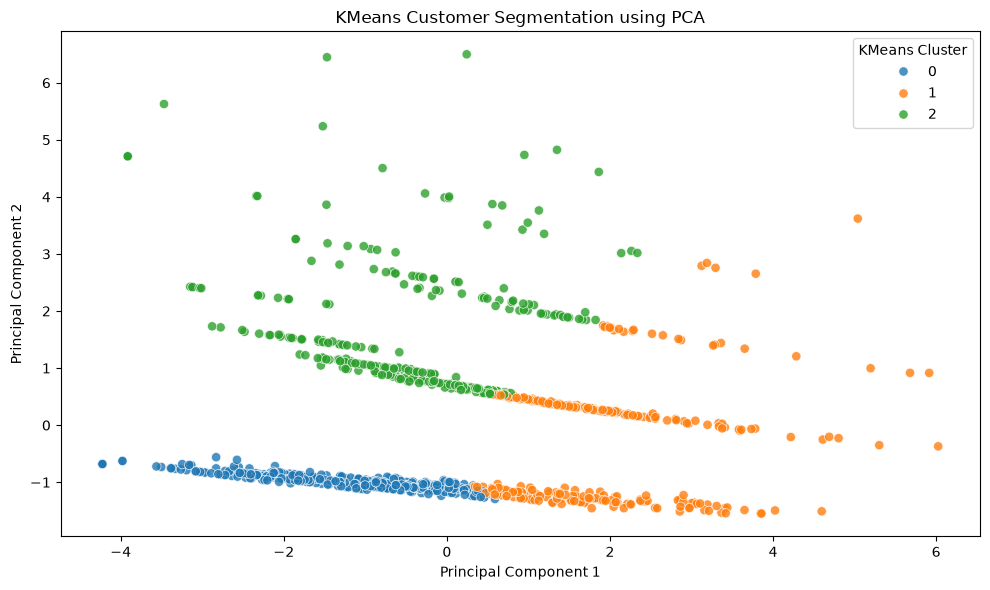

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=customer_features,
    x="PCA1",
    y="PCA2",
    hue="kmeans_cluster",
    palette="tab10",
    s=45,
    alpha=0.8
)

plt.title("KMeans Customer Segmentation using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="KMeans Cluster")
plt.tight_layout()
plt.show()

In [14]:
from sklearn.metrics import silhouette_score

# KMeans silhouette score
kmeans_silhouette = silhouette_score(
    X_scaled,
    customer_features["kmeans_cluster"]
)

# DBSCAN silhouette score (exclude noise points)
mask = customer_features["dbscan_cluster"] != -1
dbscan_labels = customer_features.loc[mask, "dbscan_cluster"]

if dbscan_labels.nunique() > 1:
    dbscan_silhouette = silhouette_score(
        X_scaled[mask],
        dbscan_labels
    )
else:
    dbscan_silhouette = None

print("KMeans silhouette score:", round(kmeans_silhouette, 3))
print("DBSCAN silhouette score:", 
      round(dbscan_silhouette, 3) if dbscan_silhouette is not None else "Not available")
print("DBSCAN noise percentage:", round((~mask).mean() * 100, 2), "%")

KMeans silhouette score: 0.33
DBSCAN silhouette score: 0.219
DBSCAN noise percentage: 4.8 %
